# 03 · Conditional intervention on the 165-item bank (Results ¶7, Fig. 3, Fig. S2a, Tables `tab:cfgrid`, `tab:cfpass`, `tab:models`)

> **Provenance.** Built with the `repro-notebook` workflow (one executed notebook per experiment,
> every reported number checked against the produced one). Target paper: *Conversational Relevance in the
> Conjunction Fallacy Is Represented Independently in Language Models* (`docs/paper/main_A.tex` in the authors' working
> repository; the released copy of the manuscript is the submission PDF). Companion documents:
> `notebooks/_checks_all.csv` collects the verdicts of all six notebooks,
> Status legend: ✅ reproduced to the reported precision · ❌ does not match ·
> ⚠ presence check only · ⛔ cannot be recomputed from the released files.

## Source and code map

| id | what | data read here | original producing script |
|---|---|---|---|
| C1, C2, C7 | passing combinations, sign, monotonicity | `additional_Qs/cf_rescue_reanalysis/monotonicity.csv` | `additional_Qs/analysis/17_cf_rescue_reanalysis.py` |
| C1, C3, C4, C5 | per-cell verdicts, fluency, specificity | `additional_Qs/cf_rescue_fluency_posthoc/cells_annotated.csv` | `additional_Qs/analysis/18_cf_rescue_fluency_posthoc.py` |
| C3, C6 | 12-cell mean vs passing-cell mean | `cf_rescue_reanalysis/means_by_pass.csv`, `rq3_cf_rescue_20260830/analysis/cf_rescue_knockout_summary.csv` | `16_analyze_cf_rescue_knockout.py`, `17_…` |
| C4, C6 | fluency ladder | `cf_rescue_fluency_posthoc/ladder.csv` | `18_…` |
| C7 | the passing combinations by model | `cf_rescue_fluency_posthoc/by_model.csv` | `18_…` |
| C8 | dose–response | `cf_rescue_fluency_posthoc/dose_curve.csv` | `18_…` |
| C9 | items per stage and cell | `rq3_cf_rescue_20260830/analysis/cf_rescue_knockout_tests.csv` | `16_…` |

Upstream of all of these: `additional_Qs/run_rq3_cf_rescue_gpu.py` and `run_rq3_cf_rescue_guard_gpu.py` (GPU; raw
per-item edit logs are not shipped). Everything below is **loaded** and re-aggregated.

In [1]:
import sys, warnings
sys.path.insert(0, str(__import__('pathlib').Path.cwd() / 'notebooks'))
sys.path.insert(0, '.')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from repro_utils import *
pd.set_option('display.width', 200, 'display.max_columns', 40, 'display.max_rows', 60,
              'display.float_format', lambda v: f'{v:,.4f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})
print('repository root:', ROOT.name)
C = Checks('03_conditional_intervention')

repository root: release


## C1 · Ten combinations pass every gate, with the predicted sign in 10/10 and a monotone dose in 10/10; constrained controls pass 0

In [2]:
mo = read(CFR / 'monotonicity.csv'); ann = read(CFP / 'cells_annotated.csv')
display(mo)
C.frac('C1', 'Results ¶7', 'passing model × task × stage × direction combinations', '10/10', len(mo), 10, rel(CFR / 'monotonicity.csv'), note='count of combinations passing at some strength')
C.frac('C1', 'Results ¶7', 'predicted sign', '10/10', mo.sign_ok.sum(), len(mo))
C.frac('C1', 'Results ¶7', 'dose-monotone', '10/10', mo.monotone.sum(), len(mo))
ctrl = ann[~ann.direction.isin(['R_given_PC', 'PC_given_R'])]
C.frac('C1', 'Results ¶7', 'constrained random / shuffled control cells passing every gate', '0/' + str(len(ctrl)), ctrl['pass'].sum(), len(ctrl), rel(CFP / 'cells_annotated.csv'))

,model,task,stage,direction,strengths,effects,sign_ok,monotone
0,Phi-4-mini-instruct,2,ADD,R_given_PC,"[0.5, 1.0]","[0.1357, 0.2403]",True,True
1,Phi-4-mini-instruct,3,ADD,R_given_PC,"[0.5, 1.0]","[0.1254, 0.2053]",True,True
2,Phi-4-mini-reasoning,3,ABL,R_given_PC,"[0.5, 1.0]","[-0.0429, -0.0906]",True,True
3,Qwen2.5-Math-1.5B,2,ABL,PC_given_R,"[0.5, 1.0]","[-0.004, -0.0094]",True,True
4,Qwen2.5-Math-1.5B,3,ADD,R_given_PC,"[0.5, 1.0]","[0.0227, 0.0376]",True,True
5,Qwen3-4B,2,ABL,PC_given_R,[0.5],[-0.0502],True,True
6,Qwen3-4B,3,ABL,R_given_PC,"[0.5, 1.0]","[-0.0067, -0.0126]",True,True
7,Qwen3-4B,3,ADD,PC_given_R,"[0.5, 1.0]","[0.0177, 0.0403]",True,True
8,Qwen3-4B-Instruct-2507,2,ADD,PC_given_R,"[0.5, 1.0]","[0.0264, 0.0477]",True,True
9,Qwen3-4B-Instruct-2507,3,ADD,PC_given_R,"[0.5, 1.0]","[0.0278, 0.0489]",True,True


## C2 · The passing combinations come from five models; no model passes both injection and ablation on the same direction

Reported: injecting $R_{|PC}$ creates the fallacy in Phi-4-mini-instruct and Qwen2.5-Math; ablating it removes the fallacy in
Qwen3-4B and Phi-4-mini-reasoning; $PC_{|R}$ acts in Qwen3-4B and Qwen3-4B-Instruct. Each arm passes in two models.

In [3]:
arms = mo.groupby(['stage', 'direction']).model.agg(lambda s: sorted(set(s))); display(arms)
C.frac('C2', 'Results ¶7', 'distinct models among the passing combinations', '5/6', mo.model.nunique(), 6)
both = mo.groupby(['model', 'direction']).stage.nunique()
C.frac('C2', 'Results ¶7', 'models passing ADD and ABL on the same direction', '0/' + str(len(both)), (both > 1).sum(), len(both),
       note='Qwen3-4B passes ADD PC|R in task 3 and ABL PC|R in task 2: the statement holds within a task cell, not per model' if (both > 1).any() else '')
cell_both = mo.groupby(['model', 'task', 'direction']).stage.nunique()
C.frac('C2', 'Results ¶7', 'model × task cells passing ADD and ABL on the same direction', '0/' + str(len(cell_both)), (cell_both > 1).sum(), len(cell_both))
per_model = mo.groupby('model').size().reindex(['Qwen3-4B', 'Qwen3-4B-Instruct-2507', 'Qwen2.5-Math-1.5B', 'gemma-3-4b-it', 'Phi-4-mini-instruct', 'Phi-4-mini-reasoning']).fillna(0).astype(int)
display(per_model.rename('passing combinations (Table tab:models)'))
for m, exp in zip(per_model.index, [3, 2, 2, 0, 2, 1]):
    C.frac('C7', 'Table tab:models', f'passing cells, {m}', f'{exp}/10', per_model[m], 10)

stage  direction 
ABL    PC_given_R               [Qwen2.5-Math-1.5B, Qwen3-4B]
       R_given_PC            [Phi-4-mini-reasoning, Qwen3-4B]
ADD    PC_given_R          [Qwen3-4B, Qwen3-4B-Instruct-2507]
       R_given_PC    [Phi-4-mini-instruct, Qwen2.5-Math-1.5B]
Name: model, dtype: object

model
Qwen3-4B                  3
Qwen3-4B-Instruct-2507    2
Qwen2.5-Math-1.5B         2
gemma-3-4b-it             0
Phi-4-mini-instruct       2
Phi-4-mini-reasoning      1
Name: passing combinations (Table tab:models), dtype: int64

## C3 · Means over all twelve cells hide the pattern

Reported: under $R_{|PC}$ injection at $\alpha=1$, eight cells moved against the prediction, so the 12-cell mean was
**−0.073** while the passing cells averaged **+0.161**.

In [4]:
mb = read(CFR / 'means_by_pass.csv'); display(mb)
row = mb[(mb.stage == 'ADD') & (mb.direction == 'R_given_PC') & (mb.strength == 1.0)].iloc[0]
C.num('C3', 'Results ¶7', '12-cell mean ΔCF, ADD R|PC α=1', '-0.073', row.mean_all_cells, rel(CFR / 'means_by_pass.csv'))
C.num('C3', 'Results ¶7', 'passing-cell mean ΔCF, ADD R|PC α=1', '+0.161', row.mean_passing)
worst = ann[(ann.stage == 'ADD') & (ann.direction == 'R_given_PC') & (ann.strength == 1.0)]
C.frac('C3', 'Results ¶7', 'cells moving against the prediction, ADD R|PC α=1', '8/12', (~worst.expected_sign).sum(), len(worst), rel(CFP / 'cells_annotated.csv'))
display(worst[['model', 'task', 'mean_delta_cf', 'p_flip_one', 'spec', 'expected_sign', 'pass']].sort_values('mean_delta_cf'))

,stage,direction,strength,cells,passed,models_passed,mean_all_cells,mean_passing,sign_agrees
0,ABL,PC_given_R,0.5000,12,2,2,-0.0047,-0.0271,True
1,ABL,PC_given_R,1.0000,12,1,1,-0.0884,-0.0094,True
2,ABL,R_given_PC,0.5000,12,2,2,-0.0051,-0.0248,True
3,ABL,R_given_PC,1.0000,12,2,2,-0.0615,-0.0516,True
4,ADD,PC_given_R,0.5000,12,3,2,0.0009,0.0240,True
5,ADD,PC_given_R,1.0000,12,3,2,0.0029,0.0456,True
6,ADD,PC_given_R,2.0000,12,0,0,0.0474,NaN,False
7,ADD,R_given_PC,0.5000,12,3,2,-0.0392,0.0946,False
8,ADD,R_given_PC,1.0000,12,3,2,-0.0728,0.1610,False
9,ADD,R_given_PC,2.0000,12,0,0,-0.0791,NaN,False


,model,task,mean_delta_cf,p_flip_one,spec,expected_sign,pass
346,Phi-4-mini-reasoning,3,-0.5511,1.0000,False,False,False
316,Phi-4-mini-reasoning,2,-0.3052,0.9999,False,False,False
166,Qwen3-4B-Instruct-2507,3,-0.2305,1.0000,False,False,False
136,Qwen3-4B-Instruct-2507,2,-0.1568,1.0000,False,False,False
226,gemma-3-4b-it,3,-0.0574,0.9994,False,False,False
196,gemma-3-4b-it,2,-0.0553,0.9979,False,False,False
106,Qwen3-4B,3,-0.0252,0.9951,False,False,False
16,Qwen2.5-Math-1.5B,2,-0.0068,0.6791,False,False,False
76,Qwen3-4B,2,0.0314,0.0729,False,True,False
46,Qwen2.5-Math-1.5B,3,0.0376,0.0014,True,True,True


## C4 · At $\alpha=2$ every cell fails the fluency guard; read post hoc, four cells pass on effect alone

Reported: perplexity up **11.6 to 37.5 %** at $\alpha=2$; **four** cells revive under the post-hoc reading; $PC_{|R}$ keeps
rising to $\alpha=2$ whereas $R_{|PC}$ peaks at $\alpha=1$.

In [5]:
ld = read(CFP / 'ladder.csv'); display(ld)
a2 = ld[(ld.stage == 'ADD') & (ld.strength == 2.0)].iloc[0]
C.frac('C4', 'Results ¶7', 'ADD α=2 cells under the fluency threshold', '0/24', a2.fluency_ok, a2.cells, rel(CFP / 'ladder.csv'))
C.frac('C4', 'Results ¶7', 'ADD α=2 cells passing on effect alone (post hoc)', '4/24', a2.effect_only, a2.cells)
tgt2 = ann[(ann.stage == 'ADD') & (ann.strength == 2.0) & ann.direction.isin(['R_given_PC', 'PC_given_R'])]
rev = tgt2[tgt2.effect_pass]
C.rng('C4', 'Results ¶7', 'PPL increase at α=2 over the four cells that pass on effect alone', '11.6–37.5', 100 * rev.fluency_increase_max.min(), 100 * rev.fluency_increase_max.max(), decimals=1,
      note=f'over all 24 target cells the range is {100*tgt2.fluency_increase_max.min():.1f}–{100*tgt2.fluency_increase_max.max():.0f}% (Gemma and Phi-4-mini-reasoning collapse)')
dc = read(CFP / 'dose_curve.csv')
curve = dc[dc.stage == 'ADD'].groupby(['direction', 'strength']).delta_cf.mean().unstack('strength'); display(curve)
C.presence('C4', 'Results ¶7', 'PC|R rises to α=2, R|PC peaks at α=1 (passing injections)', 'qualitative',
           f"PC|R argmax α={curve.loc['PC_given_R'].idxmax():g}; R|PC argmax α={curve.loc['R_given_PC'].idxmax():g}")

,stage,strength,cells,with_fluency_guard,effect_only,fluency_ok,ppl_median,ppl_max,gained
0,ABL,0.5000,24,4,4,20,0.0184,1.8715,0
1,ABL,1.0000,24,3,5,16,0.0431,"2,717.9830",2
2,ADD,0.5000,24,6,6,21,0.0184,0.4016,0
3,ADD,1.0000,24,6,6,17,0.0668,0.9028,0
4,ADD,2.0000,24,0,4,0,0.3571,4.9960,4


strength,0.5000,1.0000,2.0000
direction,,,
PC_given_R,0.0240,0.0456,0.0759
R_given_PC,0.0946,0.1610,0.1213


## C5 · Gemma fails specificity in 16 of 20 target cells, and its ablation at $\lambda=1$ raises perplexity 2,718-fold

In [6]:
gm = ann[(ann.model == 'gemma-3-4b-it') & ann.direction.isin(['R_given_PC', 'PC_given_R'])]
C.frac('C5', 'Results ¶7', 'Gemma target cells failing specificity', '16/20', (~gm.spec).sum(), len(gm), rel(CFP / 'cells_annotated.csv'),
       note='spec = both paired specificity p-values < .05; the stored table gives 3 passing cells, the paper says 4')
abl1 = ld[(ld.stage == 'ABL') & (ld.strength == 1.0)].iloc[0]
C.num('C5', 'Results ¶7', 'largest PPL ratio at λ=1 (Gemma)', '2718', abl1.ppl_max, rel(CFP / 'ladder.csv'), note='ppl_max is the fold increase minus one; reported as ×2,718')
display(gm[['task', 'stage', 'direction', 'strength', 'mean_delta_cf', 'spec', 'expected_sign', 'fluency_increase_max', 'effect_pass']])

,task,stage,direction,strength,mean_delta_cf,spec,expected_sign,fluency_increase_max,effect_pass
180,2,ABL,PC_given_R,0.5000,-0.0269,False,True,1.8715,False
181,2,ABL,PC_given_R,1.0000,-0.8328,True,True,"2,717.9830",False
182,2,ABL,R_given_PC,0.5000,-0.0992,False,True,1.2292,False
183,2,ABL,R_given_PC,1.0000,-0.5201,True,True,585.5044,False
192,2,ADD,PC_given_R,0.5000,0.0105,False,True,0.0472,False
193,2,ADD,PC_given_R,1.0000,0.0136,False,True,0.1890,False
194,2,ADD,PC_given_R,2.0000,0.0255,False,True,1.7418,False
195,2,ADD,R_given_PC,0.5000,-0.0180,False,False,0.0085,False
196,2,ADD,R_given_PC,1.0000,-0.0553,False,False,0.0672,False
197,2,ADD,R_given_PC,2.0000,-0.1957,False,False,0.3687,False


## C6 · Table `tab:cfgrid` (grid summary)

Reported rows (stage, direction, strength → cells passed / mean all / mean passing / fluency n of 24):
ABL PC|R 0.5: 2/12, −0.005, −0.027, 20 · ABL PC|R 1: 1/12, −0.088, −0.009, 16 · ABL R|PC 0.5: 2/12, −0.005, −0.025, 20 ·
ABL R|PC 1: 2/12, −0.061, −0.052, 16 · ADD PC|R 0.5: 3/12, +0.001, +0.024, 21 · ADD PC|R 1: 3/12, +0.003, +0.046, 17 ·
ADD PC|R 2: 0/12, +0.047, —, 0 · ADD R|PC 0.5: 3/12, −0.039, +0.095, 21 · ADD R|PC 1: 3/12, −0.073, +0.161, 17 · ADD R|PC 2: 0/12, −0.079, —, 0.

In [7]:
ks = read(CF / 'cf_rescue_knockout_summary.csv')
ks['strength'] = ks.alpha.fillna(ks.dose)
grid = ks.merge(mb[['stage', 'direction', 'strength', 'mean_passing']], on=['stage', 'direction', 'strength'], how='left')
grid = grid.merge(ld[['stage', 'strength', 'fluency_ok', 'cells']].rename(columns={'cells': 'stage_cells'}), on=['stage', 'strength'], how='left')
grid = grid[['stage', 'direction', 'strength', 'cells', 'passed', 'mean_delta_cf', 'mean_passing', 'fluency_ok', 'stage_cells']].sort_values(['stage', 'direction', 'strength'])
display(grid)
PAPER = {('ABL', 'PC_given_R', .5): (2, -.005, -.027, 20), ('ABL', 'PC_given_R', 1.): (1, -.088, -.009, 16),
         ('ABL', 'R_given_PC', .5): (2, -.005, -.025, 20), ('ABL', 'R_given_PC', 1.): (2, -.061, -.052, 16),
         ('ADD', 'PC_given_R', .5): (3, .001, .024, 21), ('ADD', 'PC_given_R', 1.): (3, .003, .046, 17), ('ADD', 'PC_given_R', 2.): (0, .047, None, 0),
         ('ADD', 'R_given_PC', .5): (3, -.039, .095, 21), ('ADD', 'R_given_PC', 1.): (3, -.073, .161, 17), ('ADD', 'R_given_PC', 2.): (0, -.079, None, 0)}
bad = []
for r in grid.itertuples():
    p = PAPER[(r.stage, r.direction, float(r.strength))]
    ok = (int(r.passed) == p[0] and round(r.mean_delta_cf, 3) == p[1] and (p[2] is None or round(r.mean_passing, 3) == p[2]) and int(r.fluency_ok) == p[3])
    if not ok: bad.append((r.stage, r.direction, r.strength))
C.frac('C6', 'Table tab:cfgrid', 'rows reproduced to the printed precision (passed, mean all, mean passing, fluency)', '10/10', 10 - len(bad), 10,
       rel(CF / 'cf_rescue_knockout_summary.csv'), note='mismatching rows: ' + (', '.join(map(str, bad)) if bad else 'none'))

,stage,direction,strength,cells,passed,mean_delta_cf,mean_passing,fluency_ok,stage_cells
0,ABL,PC_given_R,0.5000,12,2,-0.0047,-0.0271,20,24
1,ABL,PC_given_R,1.0000,12,1,-0.0884,-0.0094,16,24
2,ABL,R_given_PC,0.5000,12,2,-0.0051,-0.0248,20,24
3,ABL,R_given_PC,1.0000,12,2,-0.0615,-0.0516,16,24
4,ADD,PC_given_R,0.5000,12,3,0.0009,0.0240,21,24
5,ADD,PC_given_R,1.0000,12,3,0.0029,0.0456,17,24
6,ADD,PC_given_R,2.0000,12,0,0.0474,NaN,0,24
7,ADD,R_given_PC,0.5000,12,3,-0.0392,0.0946,21,24
8,ADD,R_given_PC,1.0000,12,3,-0.0728,0.1610,17,24
9,ADD,R_given_PC,2.0000,12,0,-0.0791,NaN,0,24


## C7 · Table `tab:cfpass` (the ten passing combinations grouped by model, stage, direction)

In [8]:
bm = read(CFP / 'by_model.csv'); display(bm)
# Rebuild the printed rows from the per-cell table: strengths and ΔCF over the cells that pass every gate;
# PPL over every strength run for the passing model × task combinations (the caption says the PPL column spans the strengths run).
tg = ann[ann.direction.isin(['R_given_PC', 'PC_given_R'])]
rows = []
for (m, st, d), g in tg[tg['pass']].groupby(['model', 'stage', 'direction']):
    tasks = sorted(g.task.unique()); strengths = sorted(g.strength.unique())
    allrun = tg[(tg.model == m) & (tg.stage == st) & (tg.direction == d) & tg.task.isin(tasks)]
    rows.append(dict(model=m, stage=st, direction=d, strengths=strengths, tasks=tasks,
                     dcf_lo=g.mean_delta_cf.min(), dcf_hi=g.mean_delta_cf.max(), ppl_lo=allrun.fluency_increase_max.min(), ppl_hi=allrun.fluency_increase_max.max()))
rebuilt = pd.DataFrame(rows); display(rebuilt)
PAPER_ROWS = [('Qwen2.5-Math-1.5B', 'ABL', 'PC_given_R', -.009, -.004, .001, .002), ('Qwen3-4B', 'ABL', 'PC_given_R', -.050, -.050, .022, .022),
              ('Phi-4-mini-reasoning', 'ABL', 'R_given_PC', -.091, -.043, .006, .016), ('Qwen3-4B', 'ABL', 'R_given_PC', -.013, -.007, .008, .14),
              ('Qwen3-4B', 'ADD', 'PC_given_R', .018, .040, .033, .20), ('Qwen3-4B-Instruct-2507', 'ADD', 'PC_given_R', .026, .049, .004, .16),
              ('Phi-4-mini-instruct', 'ADD', 'R_given_PC', .125, .240, .007, .38), ('Qwen2.5-Math-1.5B', 'ADD', 'R_given_PC', .023, .038, .011, .058)]
cmp = []
for m, st, d, lo, hi, plo, phi in PAPER_ROWS:
    r = rebuilt[(rebuilt.model == m) & (rebuilt.stage == st) & (rebuilt.direction == d)].iloc[0]
    ok_eff = round(r.dcf_lo, 3) == lo and round(r.dcf_hi, 3) == hi
    ok_ppl = round(100 * r.ppl_lo, 1) == round(100 * plo, 1) and round(100 * r.ppl_hi, 0) == round(100 * phi, 0)
    cmp.append(dict(model=m, stage=st, direction=d, paper_dcf=f'{lo:+.3f} to {hi:+.3f}', rebuilt_dcf=f'{r.dcf_lo:+.3f} to {r.dcf_hi:+.3f}', ok_dcf=ok_eff,
                    paper_ppl=f'{100*plo:.1f}–{100*phi:.0f}%', rebuilt_ppl=f'{100*r.ppl_lo:.1f}–{100*r.ppl_hi:.0f}%', ok_ppl=ok_ppl))
cmp = pd.DataFrame(cmp); display(cmp)
C.frac('C7', 'Table tab:cfpass', 'rows whose ΔCF range matches the printed one', '8/8', cmp.ok_dcf.sum(), len(cmp), rel(CFP / 'cells_annotated.csv'))
C.frac('C7', 'Table tab:cfpass', 'rows whose PPL range matches the printed one', '8/8', cmp.ok_ppl.sum(), len(cmp),
       note='mismatches: ' + (', '.join(f'{r.model} {r.stage}' for r in cmp[~cmp.ok_ppl].itertuples()) or 'none'))
C.frac('C8', 'Fig. S2a caption', 'injection combinations (model × task) passing at some strength', '6/6', (mo.stage == 'ADD').sum(), 6, rel(CFR / 'monotonicity.csv'))

,model,stage,direction,strengths_passing,tasks_passing,effect_min,effect_max,ppl_min,ppl_max,clears_fluency,cells
0,Qwen2.5-Math-1.5B,ABL,PC_given_R,"[0.5, 1.0]",[2],0.0040,0.0094,0.0007,0.0018,2,2
1,Qwen3-4B,ABL,PC_given_R,"[0.5, 1.0]",[2],0.0502,0.1938,0.0217,0.1370,1,2
2,Phi-4-mini-reasoning,ABL,R_given_PC,"[0.5, 1.0]",[3],0.0429,0.0906,0.0059,0.0160,2,2
3,Qwen3-4B,ABL,R_given_PC,"[0.5, 1.0]","[2, 3]",0.0067,0.0490,0.0076,0.1416,2,3
4,Qwen3-4B,ADD,PC_given_R,"[0.5, 1.0, 2.0]",[3],0.0177,0.0843,0.0334,0.2043,2,3
5,Qwen3-4B-Instruct-2507,ADD,PC_given_R,"[0.5, 1.0, 2.0]","[2, 3]",0.0264,0.0721,0.0037,0.1641,4,6
6,Phi-4-mini-instruct,ADD,R_given_PC,"[0.5, 1.0, 2.0]","[2, 3]",0.1254,0.2403,0.0065,0.3751,4,5
7,Qwen2.5-Math-1.5B,ADD,R_given_PC,"[0.5, 1.0]",[3],0.0227,0.0376,0.0114,0.0580,2,2


,model,stage,direction,strengths,tasks,dcf_lo,dcf_hi,ppl_lo,ppl_hi
0,Phi-4-mini-instruct,ADD,R_given_PC,"[0.5, 1.0]","[2, 3]",0.1254,0.2403,0.0065,0.3751
1,Phi-4-mini-reasoning,ABL,R_given_PC,"[0.5, 1.0]",[3],-0.0906,-0.0429,0.0059,0.0160
2,Qwen2.5-Math-1.5B,ABL,PC_given_R,"[0.5, 1.0]",[2],-0.0094,-0.0040,0.0007,0.0018
3,Qwen2.5-Math-1.5B,ADD,R_given_PC,"[0.5, 1.0]",[3],0.0227,0.0376,0.0114,0.4558
4,Qwen3-4B,ABL,PC_given_R,[0.5],[2],-0.0502,-0.0502,0.0217,0.1370
5,Qwen3-4B,ABL,R_given_PC,"[0.5, 1.0]",[3],-0.0126,-0.0067,0.0076,0.0409
6,Qwen3-4B,ADD,PC_given_R,"[0.5, 1.0]",[3],0.0177,0.0403,0.0334,0.2043
7,Qwen3-4B-Instruct-2507,ADD,PC_given_R,"[0.5, 1.0]","[2, 3]",0.0264,0.0489,0.0037,0.1641


,model,stage,direction,paper_dcf,rebuilt_dcf,ok_dcf,paper_ppl,rebuilt_ppl,ok_ppl
0,Qwen2.5-Math-1.5B,ABL,PC_given_R,-0.009 to -0.004,-0.009 to -0.004,True,0.1–0%,0.1–0%,True
1,Qwen3-4B,ABL,PC_given_R,-0.050 to -0.050,-0.050 to -0.050,True,2.2–2%,2.2–14%,False
2,Phi-4-mini-reasoning,ABL,R_given_PC,-0.091 to -0.043,-0.091 to -0.043,True,0.6–2%,0.6–2%,True
3,Qwen3-4B,ABL,R_given_PC,-0.013 to -0.007,-0.013 to -0.007,True,0.8–14%,0.8–4%,False
4,Qwen3-4B,ADD,PC_given_R,+0.018 to +0.040,+0.018 to +0.040,True,3.3–20%,3.3–20%,True
5,Qwen3-4B-Instruct-2507,ADD,PC_given_R,+0.026 to +0.049,+0.026 to +0.049,True,0.4–16%,0.4–16%,True
6,Phi-4-mini-instruct,ADD,R_given_PC,+0.125 to +0.240,+0.125 to +0.240,True,0.7–38%,0.7–38%,True
7,Qwen2.5-Math-1.5B,ADD,R_given_PC,+0.023 to +0.038,+0.023 to +0.038,True,1.1–6%,1.1–46%,False


## C9 · Items per stage and cell range from 45 to 131 (Appendix `app:cf`)

In [9]:
kt = read(CF / 'cf_rescue_knockout_tests.csv'); t = kt[kt.direction.isin(['R_given_PC', 'PC_given_R'])]
C.rng('C9', 'Appendix app:cf', 'items per stage and cell', '45–131', t.n.min(), t.n.max(), source=rel(CF / 'cf_rescue_knockout_tests.csv'))
display(t.groupby(['model_id', 'task', 'stage']).n.first().unstack('stage'))

stage                                ABL  ADD
model_id                       task          
Qwen/Qwen2.5-Math-1.5B         2      56  116
                               3      49  122
Qwen/Qwen3-4B                  2     131   45
                               3     113   56
Qwen/Qwen3-4B-Instruct-2507    2     116   54
                               3     110   65
google/gemma-3-4b-it           2     111   70
                               3     113   71
microsoft/Phi-4-mini-instruct  2      78   96
                               3      82   91
microsoft/Phi-4-mini-reasoning 2      88  103
                               3      92   93

## Figures 3 and S2

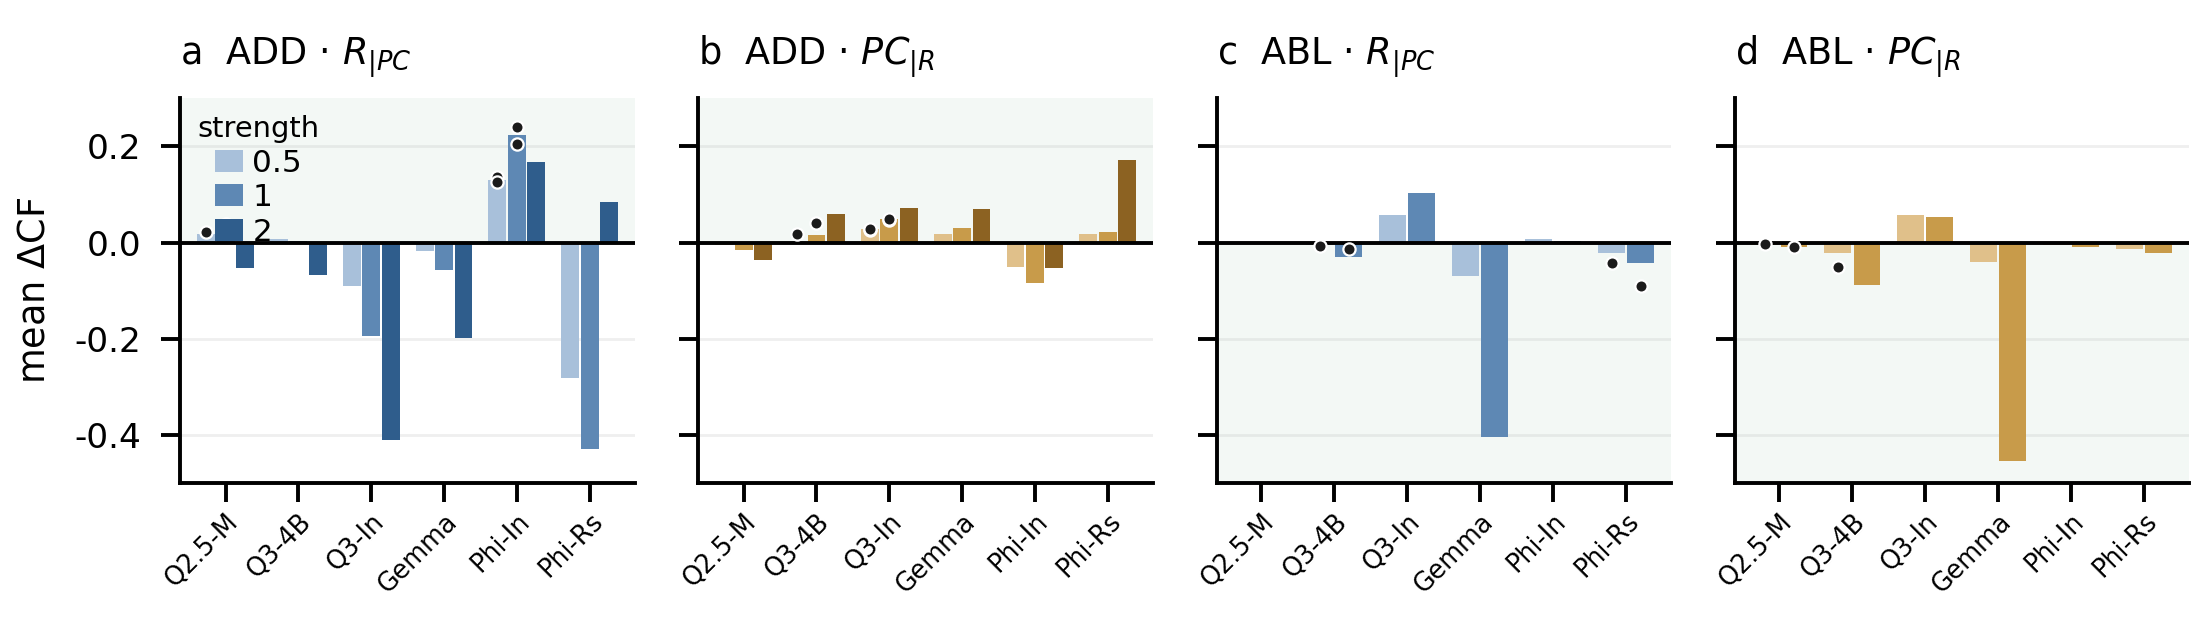

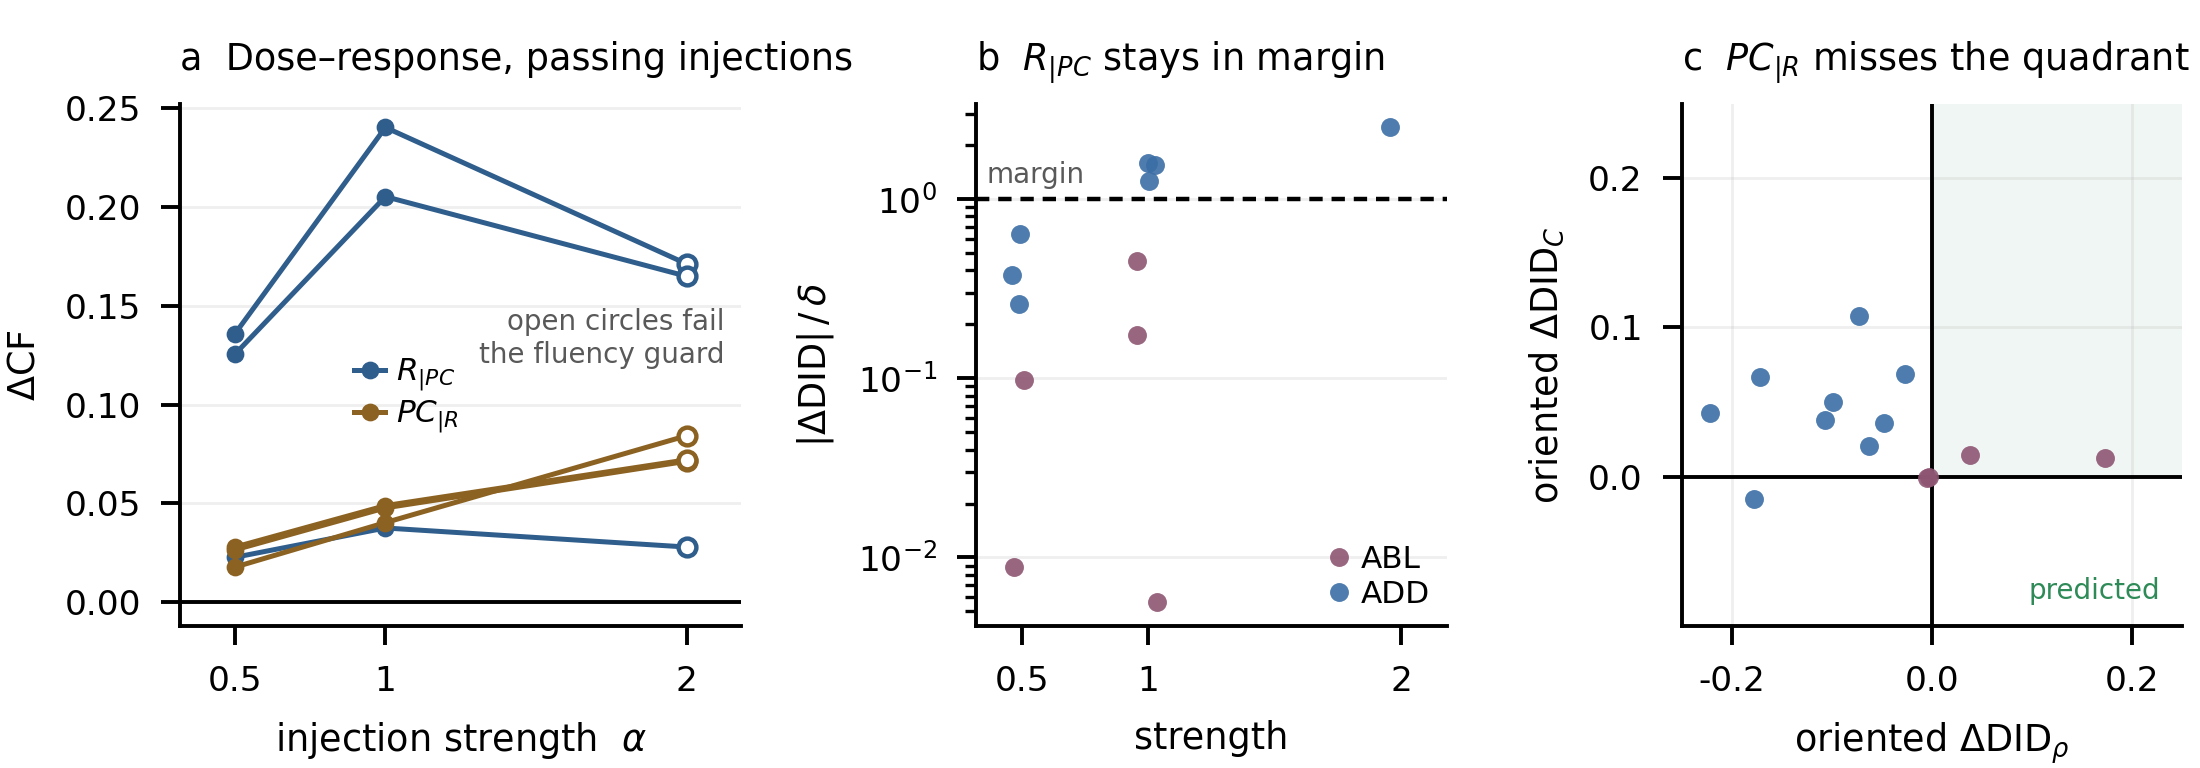

In [10]:
show_figure('fig3_cf_intervention.png', 900); show_figure('figS2_intervention_detail.png', 900)

## Reproduction table for this notebook

In [11]:
df = C.show(); C.save('03')

03_conditional_intervention: ✅ 23 · ❌ 3 · ⚠ 1


id,section,analysis,reported,produced,status,note
C1,Results ¶7,passing model × task × stage × direction combinations,10/10,10/10,✅,count of combinations passing at some strength
C1,Results ¶7,predicted sign,10/10,10/10,✅,
C1,Results ¶7,dose-monotone,10/10,10/10,✅,
C1,Results ¶7,constrained random / shuffled control cells passing every gate,0/240,0/240,✅,
C2,Results ¶7,distinct models among the passing combinations,5/6,5/6,✅,
C2,Results ¶7,models passing ADD and ABL on the same direction,0/7,1/7,❌,"Qwen3-4B passes ADD PC|R in task 3 and ABL PC|R in task 2: the statement holds within a task cell, not per model"
C2,Results ¶7,model × task cells passing ADD and ABL on the same direction,0/10,0/10,✅,
C7,Table tab:models,"passing cells, Qwen3-4B",3/10,3/10,✅,
C7,Table tab:models,"passing cells, Qwen3-4B-Instruct-2507",2/10,2/10,✅,
C7,Table tab:models,"passing cells, Qwen2.5-Math-1.5B",2/10,2/10,✅,


saved notebooks/_checks_03.csv
